# Практическая работа №3–4: бинарная классификация качества вина

## Задание

Загрузить `winequality-red.csv` и разделить вина на два класса:

- **Хорошее**: `quality >= 7`;
- **Некачественное**: `quality < 7`.

Построить классификатор и получить уравнение гиперплоскости, разделяющей классы.

## Постановка задачи

Каждое вино описывается вектором из 11 вещественных признаков:

$$\mathbf{x}_i=(x_{i1},x_{i2},\ldots,x_{i11}) \in \mathbb{R}^{11}.$$

После преобразования столбца `quality` ответ имеет два значения:

$$y_i=\begin{cases}
1, & quality_i \ge 7 \quad (\text{хорошее}),\\
0, & quality_i < 7 \quad (\text{некачественное}).
\end{cases}$$

Это **обучение с учителем**, потому что для каждого объекта известен правильный ответ, и **бинарная классификация**, потому что классов два.

## Теория: логистическая регрессия

Сначала модель вычисляет линейную комбинацию признаков:

$$z(\mathbf{x})=b+\mathbf{w}^{T}\mathbf{x}=b+\sum_{j=1}^{11}w_jx_j.$$

Затем функция сигмоиды переводит любое число $z$ в вероятность хорошего вина:

$$P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}.$$

Правило классификации при пороге 0.5:

$$\hat{y}=\begin{cases}1,&P(y=1\mid\mathbf{x})\ge0.5,\\0,&P(y=1\mid\mathbf{x})<0.5.\end{cases}$$

Так как $\sigma(0)=0.5$, граница между классами задаётся уравнением гиперплоскости:

$$b+\sum_{j=1}^{11}w_jx_j=0.$$

Точки с $z\ge0$ относятся к хорошему вину, с $z<0$ — к некачественному.

### Как обучается модель

Логистическая регрессия минимизирует бинарную кросс-энтропию:

$$L(\mathbf{w},b)=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\ln p_i+(1-y_i)\ln(1-p_i)\right],$$

где $p_i=\sigma(z_i)$. Правильные уверенные прогнозы дают малую ошибку, уверенные неправильные — большую.

`LogisticRegression` также использует L2-регуляризацию, которая ограничивает слишком большие коэффициенты. Параметр $C$ задаёт обратную силу регуляризации: чем меньше $C$, тем сильнее штраф.

In [1]:
# Работа с файлами и таблицами.
from pathlib import Path
import numpy as np
import pandas as pd

# Визуализация.
import matplotlib.pyplot as plt
import seaborn as sns

# Подготовка данных и модель.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Метрики классификации.
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
pd.set_option('display.float_format', lambda value: f'{value:.6g}')

In [2]:
DATA_FILE = Path('winequality-red.csv')
if not DATA_FILE.exists():
    raise FileNotFoundError(f'Файл не найден: {DATA_FILE.resolve()}')

# В новом CSV разделитель — запятая, поэтому sep указывать не требуется.
wine = pd.read_csv(DATA_FILE)

# Проверяем наличие целевого столбца до дальнейших вычислений.
if 'quality' not in wine.columns:
    raise ValueError('В датасете отсутствует столбец quality')

print(f'Размер датасета: {wine.shape[0]} строк × {wine.shape[1]} столбцов')
print(f'Пропущенных значений: {wine.isna().sum().sum()}')
print(f'Полностью совпадающих строк: {wine.duplicated().sum()}')
wine.head()

Размер датасета: 1599 строк × 12 столбцов
Пропущенных значений: 0
Полностью совпадающих строк: 240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.7,0,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0,2.6,0.098,25,67,0.9968,3.2,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15,54,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17,60,0.998,3.16,0.58,9.8,6
4,7.4,0.7,0,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5


Точные совпадения строк не удаляем автоматически: без идентификатора образца нельзя доказать, что это ошибки, а не повторные измерения. Важно применять одно и то же правило подготовки данных при обучении и использовании модели.

,Класс,Количество,"Доля, %"
0,Некачественное,1382,86.429
1,Хорошее,217,13.571


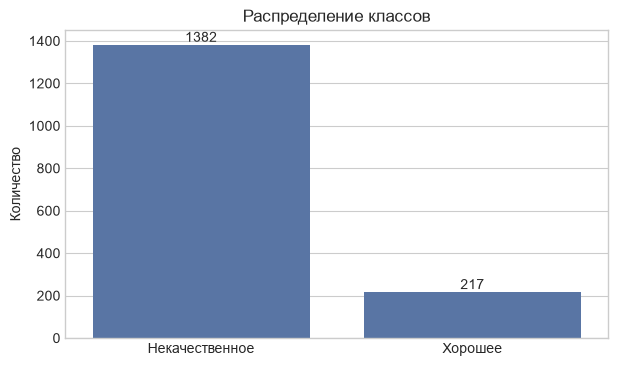

In [3]:
# X содержит химические характеристики, а исходный quality исключается.
X = wine.drop(columns='quality').copy()

# Превращаем числовую оценку качества в бинарный класс.
# True/False преобразуются в 1/0 методом astype(int).
y = (wine['quality'] >= 7).astype(int)

class_counts = y.value_counts().sort_index()
class_names = {0: 'Некачественное', 1: 'Хорошее'}

class_table = pd.DataFrame({
    'Класс': [class_names[index] for index in class_counts.index],
    'Количество': class_counts.values,
    'Доля, %': class_counts.values / len(y) * 100,
})
display(class_table)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=class_table, x='Класс', y='Количество', ax=ax)
ax.set_title('Распределение классов')
ax.set_xlabel('')
for container in ax.containers:
    ax.bar_label(container)
plt.show()

## Разделение данных

Модель проверяется на объектах, которых не видела при обучении:

- **обучающая выборка** — 75% объектов;
- **тестовая выборка** — 25% объектов.

`stratify=y` сохраняет долю хороших и некачественных вин в обеих частях. `random_state=42` делает разбиение воспроизводимым.

Сначала выполняется разбиение, а затем стандартизация. Иначе информация о тестовой выборке попадёт в обучение — это называется утечкой данных.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

print(f'Обучающая выборка: {X_train.shape}')
print(f'Тестовая выборка: {X_test.shape}')
print(f'Доля хороших вин в train: {y_train.mean():.3f}')
print(f'Доля хороших вин в test:  {y_test.mean():.3f}')

Обучающая выборка: (1199, 11)
Тестовая выборка: (400, 11)
Доля хороших вин в train: 0.136
Доля хороших вин в test:  0.135


## Стандартизация признаков

Признаки измеряются в разных единицах: например, `density` около 1, а `total sulfur dioxide` может быть больше 200. Стандартизация приводит каждый признак к среднему 0 и стандартному отклонению 1:

$$x'_{ij}=\frac{x_{ij}-\mu_j}{s_j}.$$

Средние $\mu_j$ и стандартные отклонения $s_j$ вычисляются **только по обучающей выборке**. Это улучшает численную устойчивость оптимизации и позволяет сравнивать стандартизованные коэффициенты.

In [5]:
scaler = StandardScaler()

# fit_transform изучает параметры масштабирования на train и преобразует train.
X_train_scaled = scaler.fit_transform(X_train)

# Для test используем уже найденные параметры, ничего не переобучая.
X_test_scaled = scaler.transform(X_test)

print('Средние стандартизованных признаков train (около 0):')
print(np.round(X_train_scaled.mean(axis=0), 6))
print('Стандартные отклонения (около 1):')
print(np.round(X_train_scaled.std(axis=0), 6))

Средние стандартизованных признаков train (около 0):
[ 0.  0. -0. -0. -0. -0. -0.  0.  0. -0. -0.]
Стандартные отклонения (около 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Обучение классификатора

Хороших вин заметно меньше. Если минимизировать обычную среднюю ошибку, модель может слишком часто выбирать большой класс. Поэтому используем `class_weight='balanced'`:

$$weight_k=\frac{n}{K\,n_k},$$

где $n$ — число объектов, $K=2$ — число классов, $n_k$ — число объектов класса $k$. Таким образом, суммарный вклад каждого класса в функцию потерь становится примерно одинаковым.

In [6]:
model = LogisticRegression(
    class_weight='balanced',  # компенсируем дисбаланс классов
    C=1.0,                    # стандартная сила L2-регуляризации
    max_iter=5000,            # достаточный предел итераций для сходимости
    random_state=42,
)

# Обучаем коэффициенты логистической регрессии только на train.
model.fit(X_train_scaled, y_train)

print(f'Модель сошлась за {model.n_iter_[0]} итераций оптимизатора.')

Модель сошлась за 15 итераций оптимизатора.


In [7]:
# predict выдаёт готовый класс при пороге вероятности 0.5.
y_pred = model.predict(X_test_scaled)

# predict_proba[:, 1] — вероятность положительного класса «Хорошее».
y_proba = model.predict_proba(X_test_scaled)[:, 1]

metrics_table = pd.DataFrame({
    'Метрика': [
        'Accuracy',
        'Balanced accuracy',
        'Precision класса «Хорошее»',
        'Recall класса «Хорошее»',
        'F1 класса «Хорошее»',
        'ROC-AUC',
    ],
    'Значение': [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
    ],
})

display(metrics_table)
print('Подробный отчёт:')
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Некачественное', 'Хорошее'],
    digits=4,
))

,Метрика,Значение
0,Accuracy,0.79
1,Balanced accuracy,0.784843
2,Precision класса «Хорошее»,0.368421
3,Recall класса «Хорошее»,0.777778
4,F1 класса «Хорошее»,0.5
5,ROC-AUC,0.871869


Подробный отчёт:
                precision    recall  f1-score   support

Некачественное     0.9580    0.7919    0.8671       346
       Хорошее     0.3684    0.7778    0.5000        54

      accuracy                         0.7900       400
     macro avg     0.6632    0.7848    0.6835       400
  weighted avg     0.8784    0.7900    0.8175       400



### Как понимать метрики

- **Accuracy** — доля всех правильных ответов. При дисбалансе может выглядеть хорошо даже у слабой модели.
- **Precision** положительного класса — какая доля вин, названных хорошими, действительно хорошая: $TP/(TP+FP)$.
- **Recall** — какую долю всех хороших вин модель нашла: $TP/(TP+FN)$.
- **F1** — гармоническое среднее precision и recall: $2PR/(P+R)$.
- **Balanced accuracy** — среднее recall двух классов; каждый класс влияет одинаково.
- **ROC-AUC** — вероятность того, что модель поставит случайному хорошему вину больший балл, чем случайному некачественному. 0.5 соответствует случайному ранжированию, 1 — идеальному.

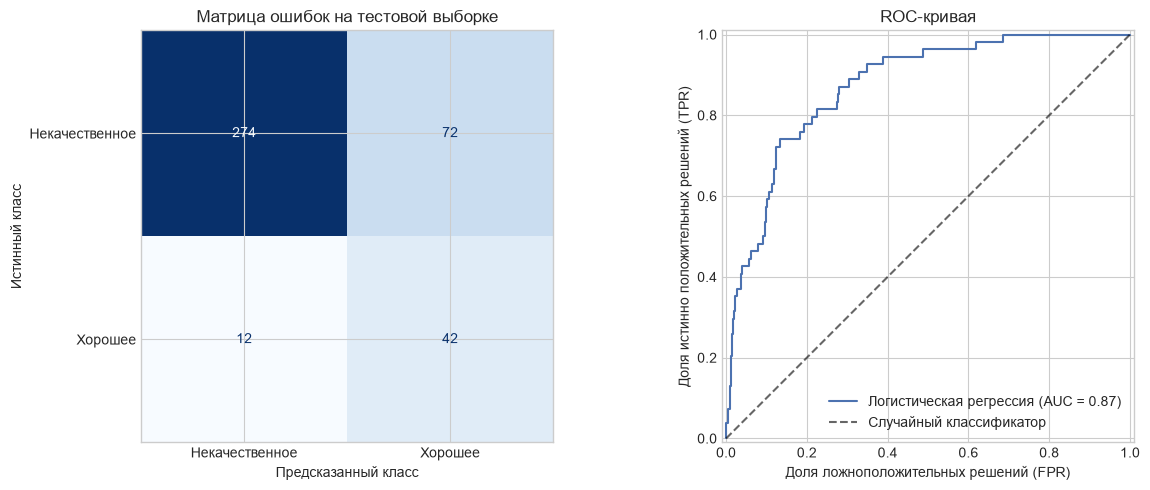

In [8]:
# Матрица ошибок содержит TN, FP, FN и TP.
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Некачественное', 'Хорошее'],
).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Матрица ошибок на тестовой выборке')
axes[0].set_xlabel('Предсказанный класс')
axes[0].set_ylabel('Истинный класс')

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name='Логистическая регрессия')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Случайный классификатор')
axes[1].set_title('ROC-кривая')
axes[1].set_xlabel('Доля ложноположительных решений (FPR)')
axes[1].set_ylabel('Доля истинно положительных решений (TPR)')
axes[1].legend()

plt.tight_layout()
plt.show()

## Коэффициенты и гиперплоскость

После стандартизации модель использует

$$z=b'+\sum_j w'_j\frac{x_j-\mu_j}{s_j}.$$

Чтобы записать уравнение через исходные признаки, раскрываем скобки:

$$w_j=\frac{w'_j}{s_j}, \qquad
b=b'-\sum_j\frac{w'_j\mu_j}{s_j}.$$

Тогда итоговая граница имеет обычный вид $b+\sum_jw_jx_j=0$.

Важно: величины исходных коэффициентов нельзя напрямую сравнивать из-за разных единиц измерения. Для сравнения влияния признаков смотрят на коэффициенты после стандартизации.

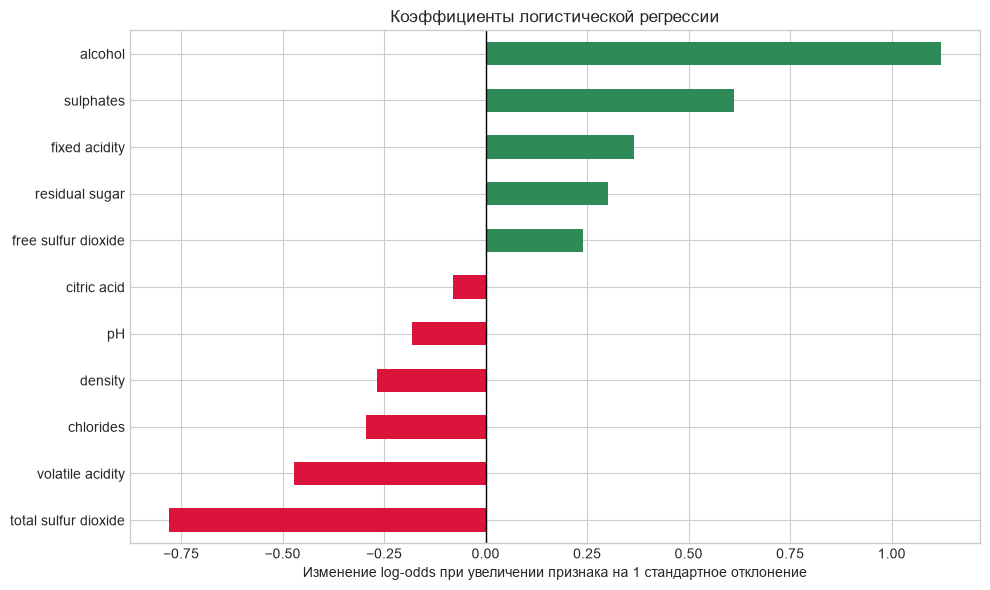

,Стандартизованный коэффициент
total sulfur dioxide,-0.780912
volatile acidity,-0.472314
chlorides,-0.293595
density,-0.267754
pH,-0.182274
citric acid,-0.0806199
free sulfur dioxide,0.240091
residual sugar,0.300793
fixed acidity,0.364452
sulphates,0.611734


In [9]:
# Стандартизованные коэффициенты можно сравнивать по модулю.
standardized_coefficients = pd.Series(
    model.coef_[0],
    index=X.columns,
    name='Стандартизованный коэффициент',
).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['crimson' if value < 0 else 'seagreen'
          for value in standardized_coefficients]
standardized_coefficients.plot.barh(ax=ax, color=colors)
ax.axvline(0, color='black', lw=1)
ax.set_title('Коэффициенты логистической регрессии')
ax.set_xlabel('Изменение log-odds при увеличении признака на 1 стандартное отклонение')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

standardized_coefficients.to_frame()

## Итоговая модель на всех данных

Тестовая модель выше нужна для честной оценки качества. После оценки обучим отдельную итоговую модель на всех доступных объектах и выведем требуемое заданием уравнение гиперплоскости. Метрики итоговой модели на тех же данных не считаем, потому что это была бы завышенная оценка.

In [10]:
# Итоговые параметры масштабирования изучаются по всему X.
final_scaler = StandardScaler()
X_scaled = final_scaler.fit_transform(X)

# Итоговую модель обучаем на всех доступных наблюдениях.
final_model = LogisticRegression(
    class_weight='balanced',
    C=1.0,
    max_iter=5000,
    random_state=42,
)
final_model.fit(X_scaled, y)

# Переводим коэффициенты в исходные единицы признаков.
weights_original = final_model.coef_[0] / final_scaler.scale_
intercept_original = (
    final_model.intercept_[0]
    - np.sum(final_model.coef_[0] * final_scaler.mean_ / final_scaler.scale_)
)

coefficient_table = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент в стандартизованной модели': final_model.coef_[0],
    'Коэффициент в исходных единицах': weights_original,
}).sort_values(
    'Коэффициент в стандартизованной модели',
    key=lambda column: column.abs(),
    ascending=False,
)
display(coefficient_table)

# Формируем читаемое уравнение. Названия признаков заключаем в квадратные скобки.
equation_terms = [
    f'{coefficient:+.8f}·[{feature}]'
    for feature, coefficient in zip(X.columns, weights_original)
]

print('Уравнение разделяющей гиперплоскости в исходных признаках:')
print(f'z(x) = {intercept_original:+.8f}')
for term in equation_terms:
    print(f'       {term}')
print('Граница классов: z(x) = 0')
print('z(x) >= 0 → «Хорошее», z(x) < 0 → «Некачественное».')

,Признак,Коэффициент в стандартизованной модели,Коэффициент в исходных единицах
10,alcohol,0.962405,0.903383
9,sulphates,0.68905,4.06629
0,fixed acidity,0.563595,0.323802
6,total sulfur dioxide,-0.506539,-0.0154033
7,density,-0.485621,-257.386
1,volatile acidity,-0.480058,-2.68183
3,residual sugar,0.385068,0.273197
4,chlorides,-0.375574,-7.98235
5,free sulfur dioxide,0.121906,0.011658
8,pH,0.0192457,0.124698


Уравнение разделяющей гиперплоскости в исходных признаках:
z(x) = +242.25047082
       +0.32380231·[fixed acidity]
       -2.68183392·[volatile acidity]
       +0.01677454·[citric acid]
       +0.27319726·[residual sugar]
       -7.98234961·[chlorides]
       +0.01165800·[free sulfur dioxide]
       -0.01540333·[total sulfur dioxide]
       -257.38593193·[density]
       +0.12469797·[pH]
       +4.06629335·[sulphates]
       +0.90338317·[alcohol]
Граница классов: z(x) = 0
z(x) >= 0 → «Хорошее», z(x) < 0 → «Некачественное».


In [11]:
# Проверим вручную формулы на первом объекте.
example = X.iloc[[0]]

# Линейный балл через полученное уравнение в исходных единицах.
z_manual = intercept_original + example.to_numpy()[0] @ weights_original
probability_manual = 1 / (1 + np.exp(-z_manual))

# Результат библиотечной модели должен совпасть с ручным расчётом.
probability_model = final_model.predict_proba(
    final_scaler.transform(example)
)[0, 1]

print(f'Исходный quality: {wine.loc[0, "quality"]}')
print(f'Линейный балл z: {z_manual:.6f}')
print(f'Вероятность хорошего вина: {probability_manual:.6f}')
print(f'Проверка через model.predict_proba: {probability_model:.6f}')
print('Класс:', 'Хорошее' if z_manual >= 0 else 'Некачественное')

Исходный quality: 5
Линейный балл z: -3.326802
Вероятность хорошего вина: 0.034663
Проверка через model.predict_proba: 0.034663
Класс: Некачественное


In [12]:
# ЦЕЛЬ ЯЧЕЙКИ: сформулировать итог по тестовым результатам понятным текстом.
# ВХОД: матрица ошибок и метрики тестовой модели.
# РЕЗУЛЬТАТ: число найденных хороших вин и объяснение компромисса recall/false positives.
# ЭТА ЯЧЕЙКА НЕ ПЕРЕОБУЧАЕТ МОДЕЛЬ — она только интерпретирует готовые результаты.

tn, fp, fn, tp = cm.ravel()

print('Вывод:')
print(
    f'На тестовой выборке модель правильно нашла {tp} из {tp + fn} хороших вин '
    f'(recall = {recall_score(y_test, y_pred):.3f}).'
)
print(
    f'Balanced accuracy = {balanced_accuracy_score(y_test, y_pred):.3f}, '
    f'ROC-AUC = {roc_auc_score(y_test, y_proba):.3f}.'
)
print(
    'Из-за редкости класса «Хорошее» balanced-веса повышают его полноту, '
    'но часть некачественных вин становится ложноположительной.'
)

Вывод:
На тестовой выборке модель правильно нашла 42 из 54 хороших вин (recall = 0.778).
Balanced accuracy = 0.785, ROC-AUC = 0.872.
Из-за редкости класса «Хорошее» balanced-веса повышают его полноту, но часть некачественных вин становится ложноположительной.
